# Demo: segmentation basics

Classification asks *what is this image?* Segmentation asks ***which pixels*** -
the model outputs a picture, not a label.

This notebook works on one real tile of the Massachusetts Buildings dataset,
downloaded on the spot, and walks through the pieces `train.py` uses on all 151
of them: class palettes, mask decoding, augmentation and IoU.

In [1]:
import os, sys
# Work from the project root, so imports and data paths match the scripts.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

## One real tile

Mnih's dataset is served as individual files, so a demo does not need the whole
3.5 GB - one image and its label map is 13 MB and about half a minute. It lands
in `data/`, which is gitignored, and is cached after the first run.

Using it in your own work means citing the thesis it came from (Mnih 2013,
*Machine Learning for Aerial Image Labeling*).

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

BASE = "https://www.cs.toronto.edu/~vmnih/data/mass_buildings/test"
TILE = "22828930_15"                       # any name from the dataset's index pages

demo = Path("data/demo")
demo.mkdir(parents=True, exist_ok=True)
files = {"image": demo / f"{TILE}.tiff", "mask": demo / f"{TILE}.tif"}

for kind, path in files.items():
    if path.exists():
        print(f"{kind}: already have {path}")
        continue
    url = f"{BASE}/{'sat' if kind == 'image' else 'map'}/{path.name}"
    print(f"{kind}: downloading {url}")
    urlretrieve(url, path)

print({kind: f"{path.stat().st_size / 1e6:.1f} MB" for kind, path in files.items()})

image: already have data/demo/22828930_15.tiff
mask: already have data/demo/22828930_15.tif
{'image': '6.8 MB', 'mask': '6.8 MB'}


## Masks are pictures, and the colour matters

The label map is an ordinary RGB image where each class has its own colour.
Massachusetts codes buildings in **red**, not white - a mask read as
"bright = building" would decode to almost all background and train a model to
predict nothing. `ClassMap` is what stops that: it holds the palette, and
`to_index` turns colours into class numbers.

classes found in the mask: [0, 1]
unknown pixels: 0
buildings cover 17.3% of the tile


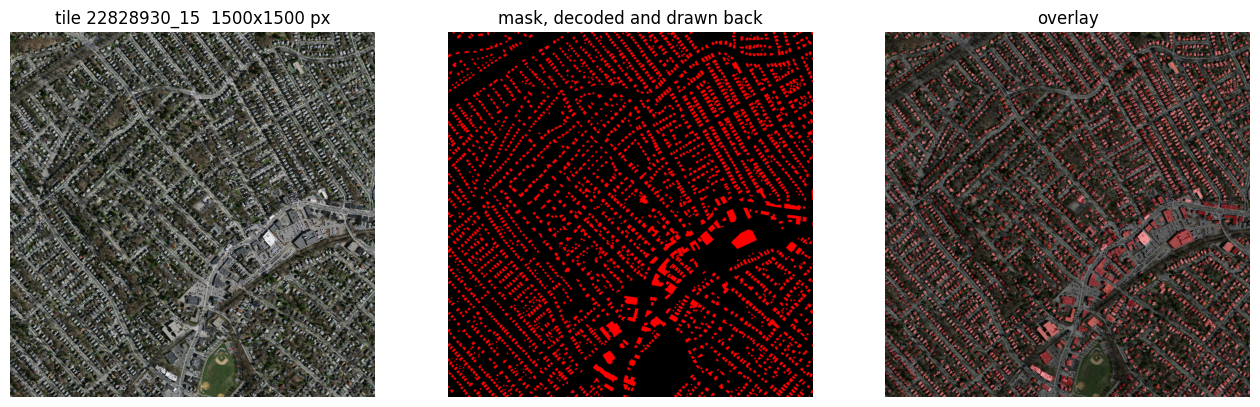

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from data import ClassMap, decode_mask, read_rgb

rng = np.random.default_rng(0)

classes = ClassMap(names=("background", "building"), palette=[[0, 0, 0], [255, 0, 0]])
tile = read_rgb(files["image"])
mask = decode_mask(files["mask"], classes)      # (H, W) of 0, 1, or 255 = unknown
mask_rgb = classes.to_rgb(mask)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
axes[0].imshow(tile);      axes[0].set_title(f"tile {TILE}  {tile.shape[0]}x{tile.shape[1]} px")
axes[1].imshow(mask_rgb);  axes[1].set_title("mask, decoded and drawn back")
axes[2].imshow(tile)
axes[2].imshow(np.where((mask == 1)[..., None], [255, 0, 0], 0).astype(np.uint8), alpha=0.35)
axes[2].set_title("overlay")
for ax in axes:
    ax.axis("off")

print("classes found in the mask:", np.unique(mask).tolist())
print(f"unknown pixels: {int((mask == 255).sum())}")
print(f"buildings cover {(mask == 1).mean():.1%} of the tile")

The round trip has to be lossless, or the training targets are silently
corrupted before the model ever sees them:

In [4]:
decoded_again = classes.to_index(mask_rgb)
print("to_index(to_rgb(mask)) == mask:", bool((decoded_again == mask).all()))

# What reading the mask as brightness instead of colour would have cost:
naive = (np.asarray(read_rgb(files["mask"])).mean(-1) > 127).astype(np.uint8)
print(f"palette-aware : {(mask == 1).mean():.1%} of pixels are building")
print(f"brightness    : {(naive == 1).mean():.1%}   <- red is not bright")

to_index(to_rgb(mask)) == mask: True
palette-aware : 17.3% of pixels are building
brightness    : 0.0%   <- red is not bright


## Augmentation: free training variety from array slicing

A building is a building rotated, so every time the network sees a tile we show
a random crop of it, sometimes mirrored. `train.py` does this with albumentations;
underneath it is just NumPy slicing:

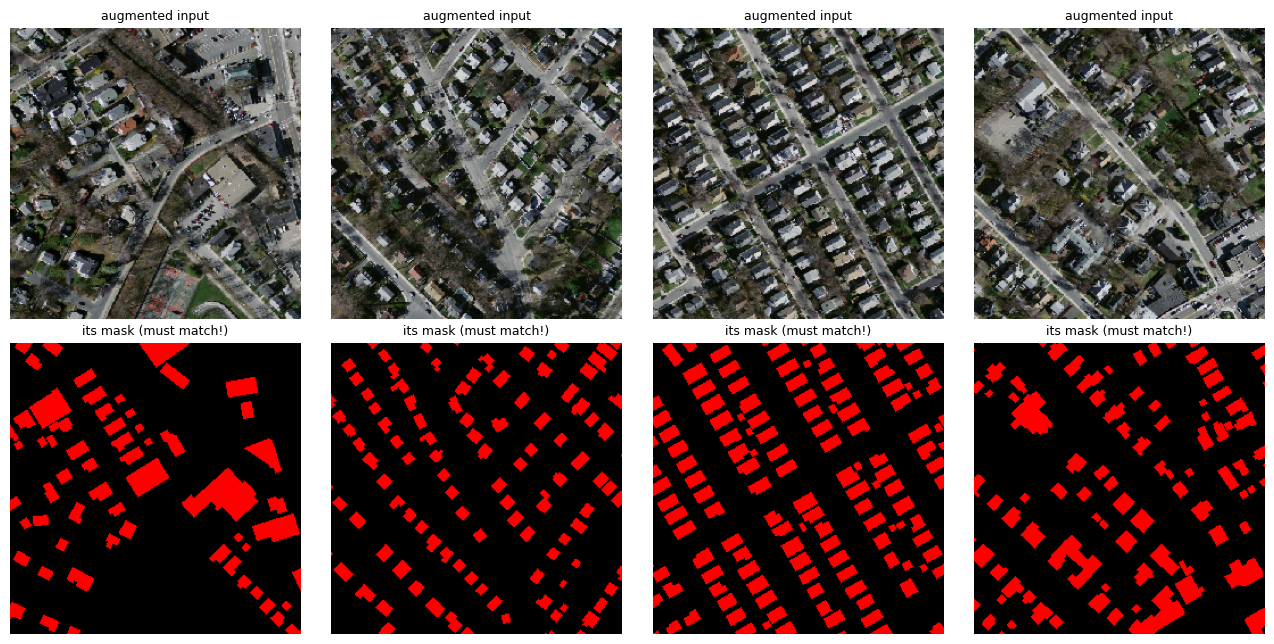

In [5]:
def random_crop(image, target, crop=256):
    y0 = rng.integers(0, image.shape[0] - crop)
    x0 = rng.integers(0, image.shape[1] - crop)
    return image[y0:y0+crop, x0:x0+crop], target[y0:y0+crop, x0:x0+crop]

def maybe_flip(image, target):
    return (image[:, ::-1], target[:, ::-1]) if rng.random() < 0.5 else (image, target)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for column in range(4):
    crop, crop_mask = maybe_flip(*random_crop(tile, mask_rgb))
    axes[0, column].imshow(crop)
    axes[1, column].imshow(crop_mask)
    axes[0, column].set_title("augmented input", fontsize=9)
    axes[1, column].set_title("its mask (must match!)", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()

## IoU - how segmentation quality is scored

Intersection-over-Union compares two painted regions: overlap divided by union,
1.0 perfect. Score two fake 'predictions' against the real mask - a sloppy one,
and the laziest model possible:

In [6]:
def iou(truth, prediction, cls=1):
    intersection = ((truth == cls) & (prediction == cls)).sum()
    union = ((truth == cls) | (prediction == cls)).sum()
    return float(intersection / max(union, 1))

sloppy = (mask == 1) | (rng.random(mask.shape) < 0.05)   # truth plus 5% noise
empty = np.zeros_like(mask)                              # "nothing is a building"

for name, prediction in (("sloppy", sloppy), ("predict-nothing", empty)):
    accuracy = ((prediction == 1) == (mask == 1)).mean()
    print(f"{name:16s} IoU {iou(mask, prediction.astype(np.uint8)):.3f}   "
          f"pixel accuracy {accuracy:.1%}")

sloppy           IoU 0.807   pixel accuracy 95.9%
predict-nothing  IoU 0.000   pixel accuracy 82.7%


That gap is the whole reason `train.py` uses a **Dice loss** rather than pixel
accuracy: a model that predicts nothing at all still scores a respectable
accuracy on this tile, and IoU 0.

**Next steps:** point `find_pairs` at the full dataset and run
`python train.py`, then `python predict.py --checkpoint runs/default/best_model.pth`
for panels like the one in the README. From there, `adapt.py` is about what
happens when the same weights meet Polish orthophotos.